In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

In [6]:
def f(x):
    return 1/(1+np.e**(-4*x))

def sim_wilson_cowan(init, dt, t_end, tau_e, tau_i, w_ee, p_e, p_i):
    t_vals = np.linspace(0, t_end, int(t_end/dt)+1)
    E_vals = np.zeros(len(t_vals))
    I_vals = np.zeros(len(t_vals))
    
    E_vals[0], I_vals[0] = init
    for i in range(1, len(t_vals)):
        E = E_vals[i-1]
        I = I_vals[i-1]
        
        dE = (-E + f(w_ee*E - 10*I + p_e))/tau_e
        dI = (-I + f(10*E + p_i))/tau_i
        
        E_vals[i] = E + dE*dt
        I_vals[i] = I + dI*dt

    return t_vals, E_vals, I_vals

In [7]:
# part i)
# set up parameters
tau_e = 5
tau_i = 10
w_ee_hopf = 25/6
eps = [.005, .01, .02, .05, .1, .2]
w_ee = [(1+e)*w_ee_hopf for e in eps]
p_e = [1 - np.log(9)/4 - w/10 for w in w_ee]
p_i = [-1 - np.log(9)/4] * 6
init_point = (.11,.11)

In [73]:
t_vals, E_vals, I_vals = sim_wilson_cowan(init_point, .002, 1600, tau_e, tau_i, w_ee[0], p_e[0], p_i[0])

In [11]:
amp = np.zeros(6)
period = np.zeros(6)
lag = np.zeros(6)

In [13]:
for i in range(6):
    t_vals, E_vals, I_vals = sim_wilson_cowan(init_point, .002, 1200, 
                                              tau_e, tau_i, 
                                              w_ee[i], p_e[i], p_i[i])
    # discard first 1000 ms
    t_cut = 1000                      
    m = t_vals >= t_cut
    tt, EE, II = t_vals[m], E_vals[m], I_vals[m]
    
    # Peak times of E and I
    dt = .002
    pk_E, _ = find_peaks(EE)
    valley_E, _ = find_peaks(-EE)
    pk_I, _ = find_peaks(II)
    tE, tI = tt[pk_E], tt[pk_I]
    
    # 4. Period: mean spacing between successive E peaks
    T = np.mean(np.diff(tE))
    E_max = np.mean(EE[pk_E])
    E_min = np.mean(EE[valley_E])
    period[i] = T
    amp[i] = E_max - E_min
    # 5. Lag of I behind E: for each E peak, find the next I peak
    lags = []
    for te in tE:
        later = tI[tI >= te]
        if len(later):
            lags.append(later[0] - te)
    lag_ms = np.mean(lags)
    lag_deg = 360 * lag_ms / T

    amp[i] = E_max - E_min
    period[i] = T
    lag[i] = lag_deg

In [15]:
print(lag)
print(period)
print(amp)

[72.62454092 70.82256608 67.95304324 62.27271782 56.39838493 49.66468465]
[12.7428     12.8476     13.0716     13.74314286 14.86       17.12363636]
[0.02336054 0.03011776 0.04098238 0.06311244 0.08813442 0.12370677]


In [77]:
slope, intercept = np.polyfit(np.log(eps), np.log(amp), 1)
print(slope)

0.4565673968748109


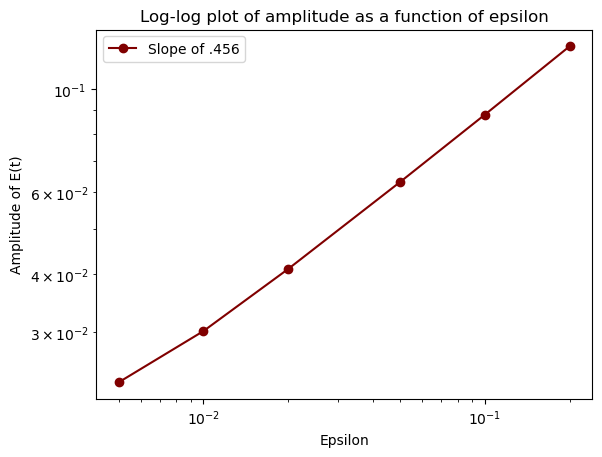

In [81]:
plt.loglog(eps, amp, '-o', color = "maroon", label = "Slope of .456")
plt.title("Log-log plot of amplitude as a function of epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Amplitude of E(t)")
plt.legend()
plt.savefig("loglog", dpi = 300, bbox_inches = "tight")
plt.show()

In [44]:
# part ii)
tau_i = [2, 3, 5, 7.5, 10, 15, 20]
w_ee_hopf = [(1 + tau_e / t) / .36 for t in tau_i]
w_ee = [1.02*h for h in w_ee_hopf]
p_e = [1 - np.log(9)/4 - w/10 for w in w_ee]
p_i = [-1 - np.log(9)/4] * 7
init_point = (.11,.11)
freq = np.zeros(7)

In [46]:
# expected frequencies
B = 16*10*10*.09*.09/5

freq_theo = [1000*np.sqrt(B/t - 1/t**2)/(2*np.pi) for t in tau_i]
freq_theo

[162.77435154984133,
 138.09742337692867,
 110.08184938319123,
 91.12537459431516,
 79.45004556900923,
 65.3031089643752,
 56.74046713092238]

In [49]:
for i in range(7):
    t_vals, E_vals, I_vals = sim_wilson_cowan(init_point, .002, 1200, 
                                              tau_e, tau_i[i], 
                                              w_ee[i], p_e[i], p_i[i])
    # discard the first 1000 ms
    t_cut = 1000                      
    m = t_vals >= t_cut
    tt, EE, II = t_vals[m], E_vals[m], I_vals[m]
    
    # Peak times of E and I
    dt = .002
    pk_E, _ = find_peaks(EE)
    pk_I, _ = find_peaks(II)
    tE, tI = tt[pk_E], tt[pk_I]

    # calculate period + frequency
    T = np.mean(np.diff(tE))
    freq[i] = 1000/T

In [50]:
print(freq)
print(freq_theo)

[156.30047203 132.79224918 105.94118146  87.72891764  76.50172894
  62.88876692  54.64242   ]
[162.77435154984133, 138.09742337692867, 110.08184938319123, 91.12537459431516, 79.45004556900923, 65.3031089643752, 56.74046713092238]


In [53]:
## part iii)
tau_i = 10
w_ee = 25/6*1.1
p_e = 1 - np.log(9)/4 - w_ee/10 
p_i = -1 - np.log(9)/4

t_vals, E_vals, I_vals = sim_wilson_cowan(init_point, .002, 200, 5, tau_i, w_ee, p_e, p_i)


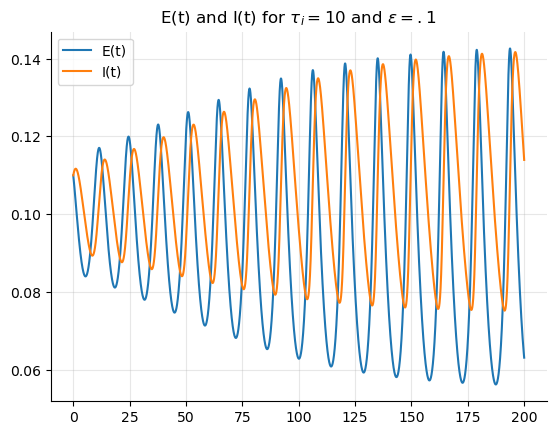

In [64]:
plt.plot(t_vals, E_vals, label = "E(t)")
plt.plot(t_vals, I_vals, label = "I(t)")
plt.title(r"E(t) and I(t) for $\tau_i = 10$ and $\epsilon = .1$")
plt.legend()
plt.grid(alpha = .3)
sns.despine()
plt.savefig("e_i_cycle", dpi = 300, bbox_inches = "tight")
plt.show()